In [13]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR100
from pathlib import Path

# 数据保存路径
data_dir = Path("../data")

# 下载训练集
train_dataset = CIFAR100(
    root=data_dir,
    train=True,
    download=True
)

# 下载测试集
test_dataset = CIFAR100(
    root=data_dir,
    train=False,
    download=True
)

print("训练集数量:", len(train_dataset))
print("测试集数量:", len(test_dataset))
print("类别数量:", len(train_dataset.classes))

# 查看第一张图片
image, label = train_dataset[0]

print("图像尺寸:", image.size)
print("类别名称:", train_dataset.classes[label])

Files already downloaded and verified
Files already downloaded and verified
训练集数量: 50000
测试集数量: 10000
类别数量: 100
图像尺寸: (32, 32)
类别名称: cattle


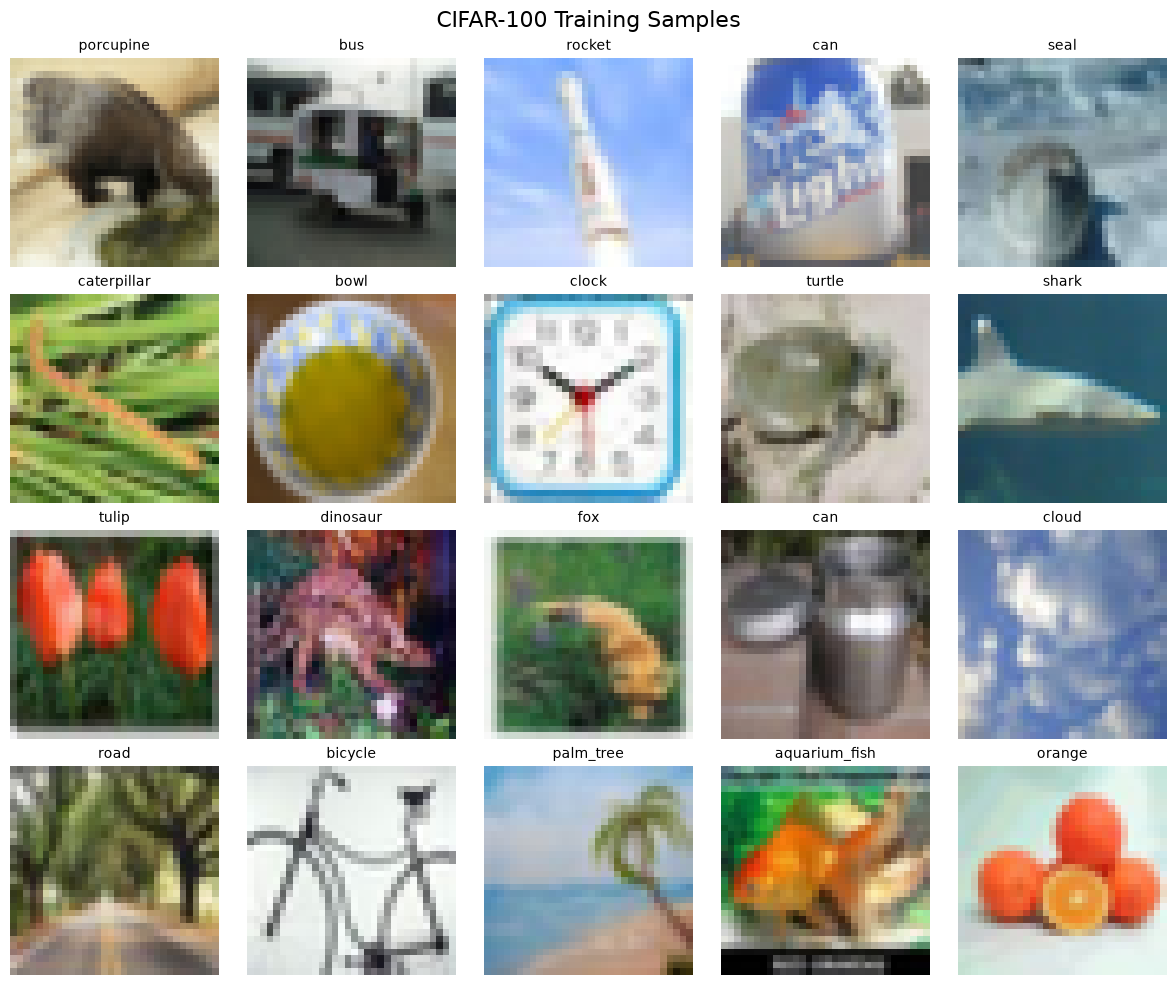

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 随机抽取20张图片
np.random.seed(42)
indices = np.random.choice(len(train_dataset), 20, replace=False)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, idx in zip(axes.flat, indices):
    image, label = train_dataset[int(idx)]

    ax.imshow(image)
    ax.set_title(train_dataset.classes[label], fontsize=10)
    ax.axis("off")

plt.suptitle("CIFAR-100 Training Samples", fontsize=16)
plt.tight_layout()

# 保存到 figures 目录
plt.savefig("../figures/cifar100_samples.png", dpi=300)
plt.show()

In [15]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from torchvision.datasets import CIFAR100

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Notebook 所在位置：mid_project/code
PROJECT_DIR = Path.cwd().resolve().parent

DATA_DIR = PROJECT_DIR / "data"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"

for folder in [DATA_DIR, FIGURE_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 调整此值可以控制实验规模
TRAIN_SIZE = 10000

print("项目路径:", PROJECT_DIR)
print("训练样本数:", TRAIN_SIZE)

项目路径: /Users/caijingxi/FZU_2026_Autumn/FZU-MachineLearning-2026/mid_project
训练样本数: 10000


加载

In [16]:
train_dataset = CIFAR100(
    root=DATA_DIR,
    train=True,
    download=False
)

test_dataset = CIFAR100(
    root=DATA_DIR,
    train=False,
    download=False
)

class_names = train_dataset.classes

print("训练集:", len(train_dataset))
print("测试集:", len(test_dataset))
print("类别数量:", len(class_names))
print("图像形状:", train_dataset.data.shape[1:])

训练集: 50000
测试集: 10000
类别数量: 100
图像形状: (32, 32, 3)


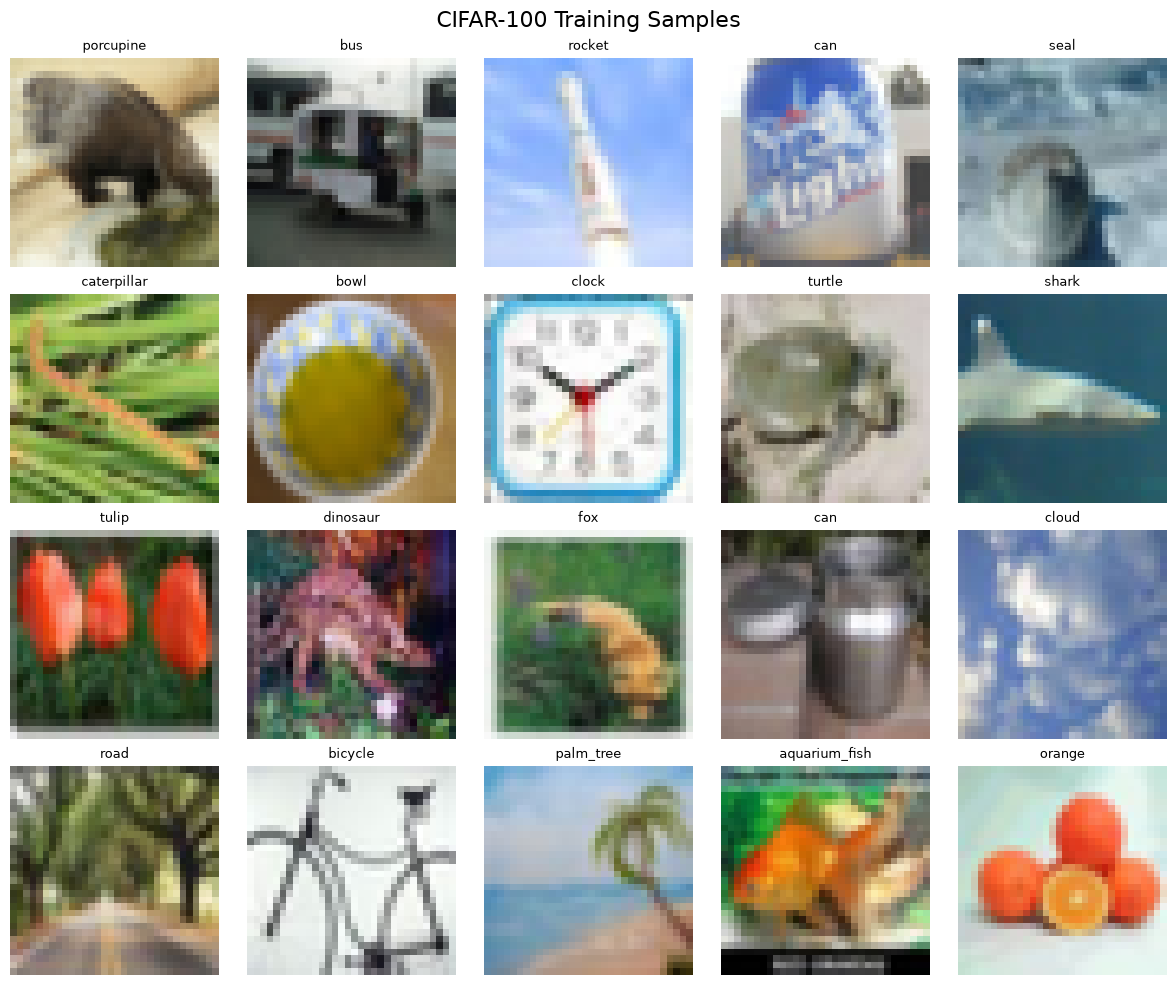

In [17]:
indices = np.random.choice(
    len(train_dataset),
    20,
    replace=False
)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for ax, idx in zip(axes.flat, indices):
    image, label = train_dataset[int(idx)]

    ax.imshow(image)
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")

plt.suptitle("CIFAR-100 Training Samples", fontsize=16)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cifar100_samples.png",
    dpi=300
)

plt.show()

预处理

In [18]:
from sklearn.model_selection import train_test_split

X_all = train_dataset.data
y_all = np.array(train_dataset.targets)

X_test_images = test_dataset.data
y_test = np.array(test_dataset.targets)

# 分层抽取训练子集
indices = np.arange(len(y_all))

train_indices, _ = train_test_split(
    indices,
    train_size=TRAIN_SIZE,
    stratify=y_all,
    random_state=RANDOM_STATE
)

X_train_images = X_all[train_indices]
y_train = y_all[train_indices]

# 展平与归一化
X_train = X_train_images.reshape(
    -1, 3072
).astype(np.float32) / 255.0

X_test = X_test_images.reshape(
    -1, 3072
).astype(np.float32) / 255.0

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("像素最小值:", X_train.min())
print("像素最大值:", X_train.max())

X_train: (10000, 3072)
X_test: (10000, 3072)
y_train: (10000,)
y_test: (10000,)
像素最小值: 0.0
像素最大值: 1.0


特征标准化

In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("标准化完成")
print("训练集:", X_train_scaled.shape)
print("测试集:", X_test_scaled.shape)

标准化完成
训练集: (10000, 3072)
测试集: (10000, 3072)


PCA

In [20]:
start = time.perf_counter()

pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_time = time.perf_counter() - start

print("原始维度:", X_train_scaled.shape[1])
print("PCA 维度:", X_train_pca.shape[1])
print(
    "累计解释方差:",
    pca.explained_variance_ratio_.sum()
)
print(f"PCA 耗时: {pca_time:.2f} 秒")

原始维度: 3072
PCA 维度: 201
累计解释方差: 0.95022523
PCA 耗时: 7.74 秒


PCA 累计解释方差曲线

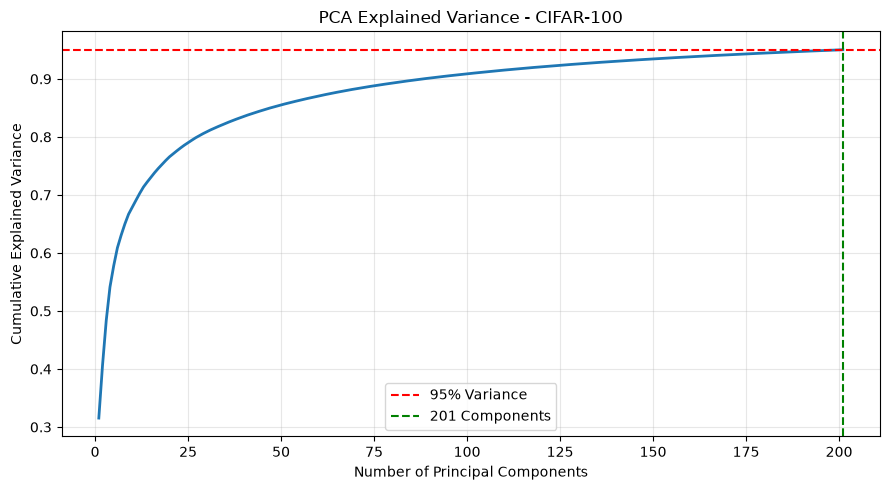

In [21]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.axvline(
    x=pca.n_components_,
    color="green",
    linestyle="--",
    label=f"{pca.n_components_} Components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance - CIFAR-100")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "pca_explained_variance.png",
    dpi=300
)
plt.show()

定义四种分类算法

In [22]:
def create_models():
    return {
        "KNN": KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        ),

        "GaussianNB": GaussianNB(),

        "LogisticRegression": LogisticRegression(
            max_iter=500,
            solver="lbfgs",
            C=1.0
        ),

        "LinearSVM": LinearSVC(
            C=0.1,
            max_iter=3000,
            random_state=RANDOM_STATE
        )
    }

定义统一训练和评价函数

In [23]:
results = []
trained_models = {}

def evaluate_model(
    name,
    model,
    X_train_data,
    X_test_data,
    feature_type
):
    start = time.perf_counter()

    model.fit(X_train_data, y_train)

    train_time = time.perf_counter() - start

    start = time.perf_counter()

    y_pred = model.predict(X_test_data)

    predict_time = time.perf_counter() - start

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Feature": feature_type,
        "Model": name,
        "Accuracy": accuracy,
        "Train_Time": train_time,
        "Predict_Time": predict_time
    })

    trained_models[(feature_type, name)] = model

    print(
        f"{feature_type:8s} | "
        f"{name:20s} | "
        f"ACC={accuracy:.4f} | "
        f"Train={train_time:.2f}s | "
        f"Predict={predict_time:.2f}s"
    )

    return y_pred

训练原始特征组

In [24]:
raw_models = create_models()

print("========== Raw Features ==========")

for name, model in raw_models.items():
    evaluate_model(
        name=name,
        model=model,
        X_train_data=X_train_scaled,
        X_test_data=X_test_scaled,
        feature_type="Raw"
    )

========== Raw Features ==========
Raw      | KNN                  | ACC=0.1199 | Train=0.01s | Predict=1.75s
Raw      | GaussianNB           | ACC=0.1098 | Train=0.05s | Predict=9.07s
Raw      | LogisticRegression   | ACC=0.0984 | Train=39.55s | Predict=0.05s
Raw      | LinearSVM            | ACC=0.0748 | Train=1659.77s | Predict=0.06s


/Users/caijingxi/miniforge3/envs/ml/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


训练 PCA 特征组

In [25]:
pca_models = create_models()

print("========== PCA Features ==========")

for name, model in pca_models.items():
    evaluate_model(
        name=name,
        model=model,
        X_train_data=X_train_pca,
        X_test_data=X_test_pca,
        feature_type="PCA"
    )

========== PCA Features ==========
PCA      | KNN                  | ACC=0.1278 | Train=0.00s | Predict=0.15s
PCA      | GaussianNB           | ACC=0.1301 | Train=0.01s | Predict=0.42s


/Users/caijingxi/miniforge3/envs/ml/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PCA      | LogisticRegression   | ACC=0.1192 | Train=6.31s | Predict=0.01s
PCA      | LinearSVM            | ACC=0.1275 | Train=379.93s | Predict=0.01s


/Users/caijingxi/miniforge3/envs/ml/lib/python3.12/site-packages/sklearn/svm/_base.py:1237: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


生成准确率对比表

In [26]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

results_df["Accuracy_Percent"] = (
    results_df["Accuracy"] * 100
)

display(results_df.round(4))

results_df.to_csv(
    RESULT_DIR / "model_comparison.csv",
    index=False
)

print("实验结果已保存")

,Feature,Model,Accuracy,Train_Time,Predict_Time,Accuracy_Percent
0,PCA,GaussianNB,0.1301,0.0065,0.4167,13.01
1,PCA,KNN,0.1278,0.0047,0.1495,12.78
2,PCA,LinearSVM,0.1275,379.9254,0.0050,12.75
3,Raw,KNN,0.1199,0.0118,1.7489,11.99
4,PCA,LogisticRegression,0.1192,6.3090,0.0053,11.92
5,Raw,GaussianNB,0.1098,0.0549,9.0739,10.98
6,Raw,LogisticRegression,0.0984,39.5548,0.0533,9.84
7,Raw,LinearSVM,0.0748,1659.7677,0.0633,7.48


实验结果已保存


准确率比较图

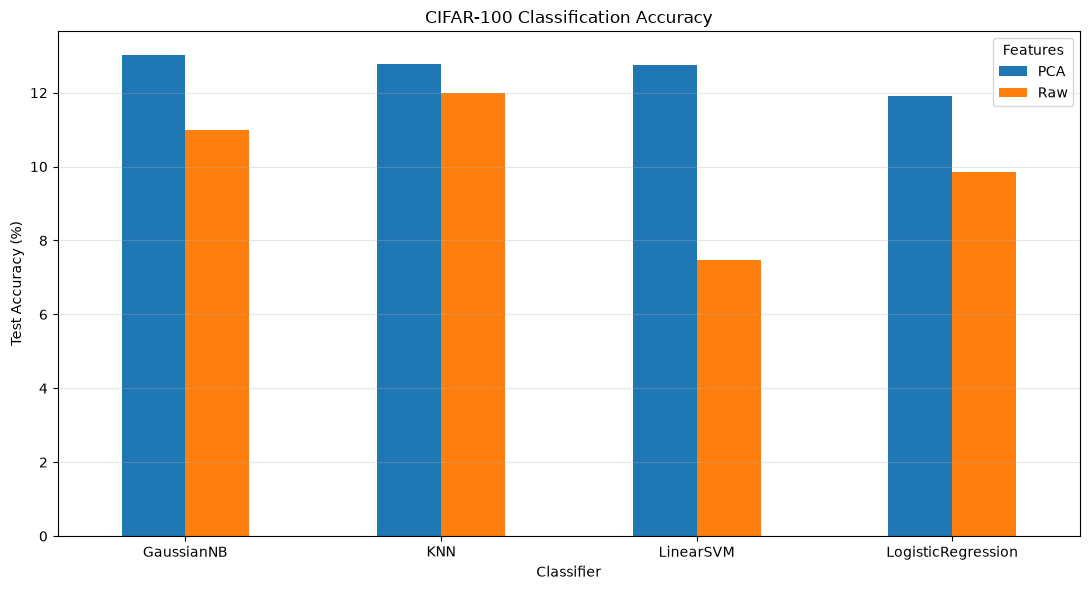

In [27]:
accuracy_table = results_df.pivot(
    index="Model",
    columns="Feature",
    values="Accuracy_Percent"
)

ax = accuracy_table.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title("CIFAR-100 Classification Accuracy")
ax.set_xlabel("Classifier")
ax.set_ylabel("Test Accuracy (%)")

ax.legend(title="Features")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "accuracy_comparison.png",
    dpi=300
)

plt.show()

训练时间比较

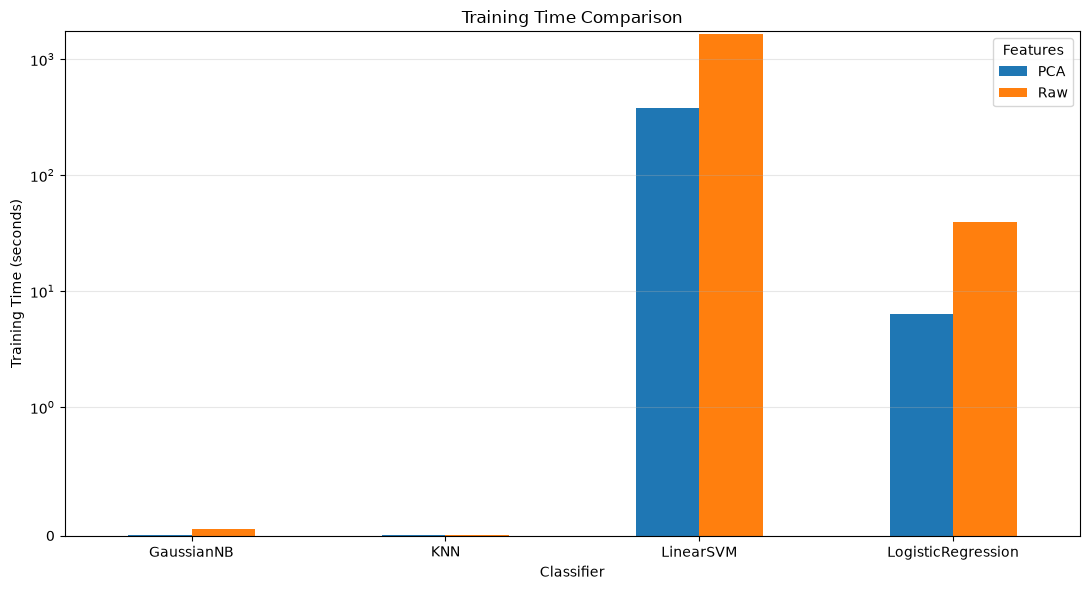

In [28]:
time_table = results_df.pivot(
    index="Model",
    columns="Feature",
    values="Train_Time"
)

ax = time_table.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title("Training Time Comparison")
ax.set_xlabel("Classifier")
ax.set_ylabel("Training Time (seconds)")
ax.set_yscale("symlog", linthresh=1)

ax.legend(title="Features")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "time_comparison.png",
    dpi=300
)

plt.show()

寻找测试准确率最高的模型

In [29]:
best_row = results_df.iloc[0]

best_feature = best_row["Feature"]
best_name = best_row["Model"]
best_accuracy = best_row["Accuracy"]

best_model = trained_models[
    (best_feature, best_name)
]

if best_feature == "PCA":
    best_X_test = X_test_pca
else:
    best_X_test = X_test_scaled

best_y_pred = best_model.predict(best_X_test)

print("最优模型:", best_name)
print("使用特征:", best_feature)
print(f"测试准确率: {best_accuracy:.4%}")

最优模型: GaussianNB
使用特征: PCA
测试准确率: 13.0100%


生成混淆矩阵

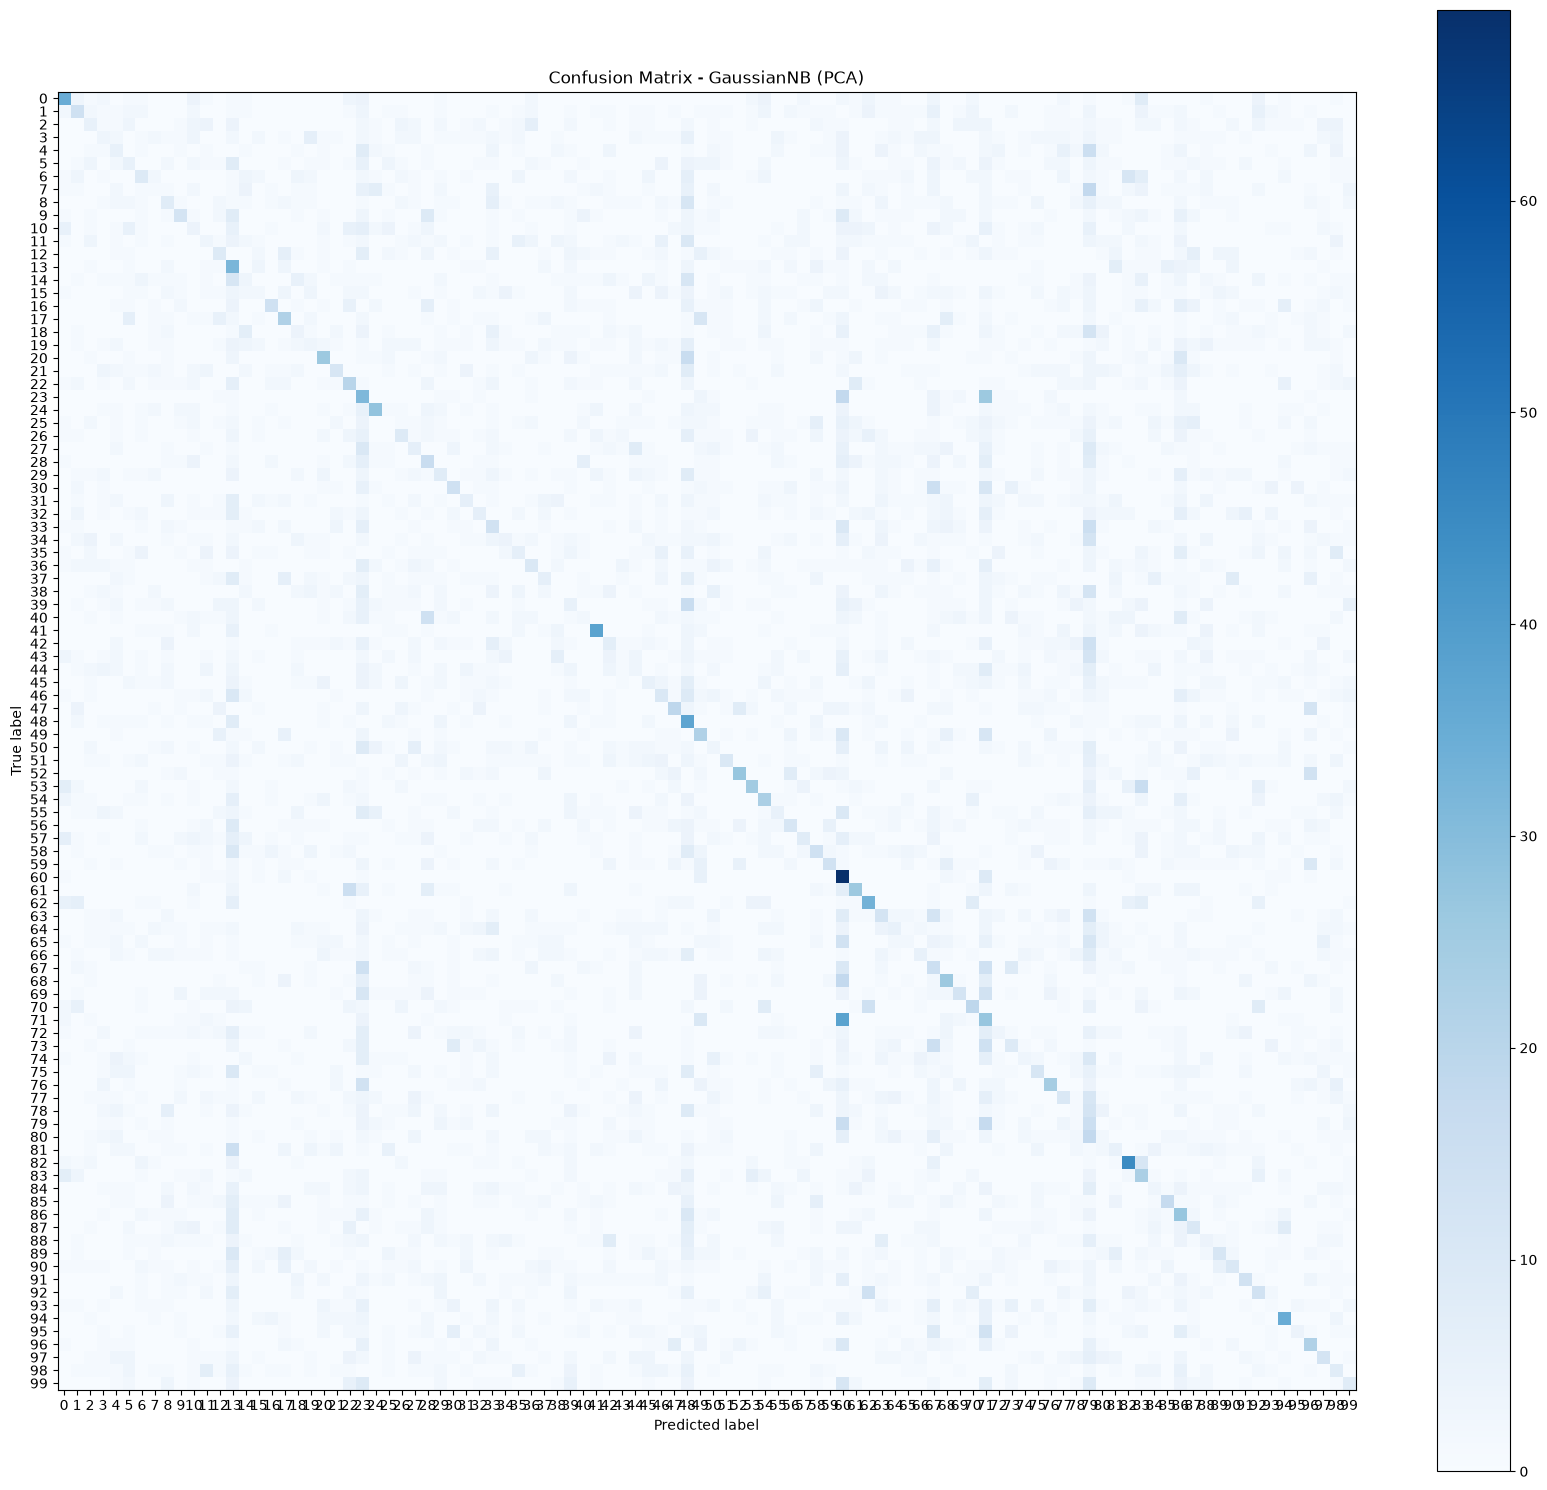

In [30]:
cm = confusion_matrix(
    y_test,
    best_y_pred,
    labels=np.arange(100)
)

fig, ax = plt.subplots(figsize=(17, 15))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    ax=ax,
    cmap="Blues",
    include_values=False,
    colorbar=True
)

ax.set_title(
    f"Confusion Matrix - {best_name} ({best_feature})"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

生成分类报告

In [31]:
report = classification_report(
    y_test,
    best_y_pred,
    labels=np.arange(100),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

with open(
    RESULT_DIR / "classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print("分类报告已保存")

               precision    recall  f1-score   support

        apple     0.3535    0.3500    0.3518       100
aquarium_fish     0.1772    0.1400    0.1564       100
         baby     0.0847    0.0500    0.0629       100
         bear     0.0492    0.0300    0.0373       100
       beaver     0.0588    0.0500    0.0541       100
          bed     0.0704    0.0500    0.0585       100
          bee     0.1286    0.0900    0.1059       100
       beetle     0.0250    0.0100    0.0143       100
      bicycle     0.0941    0.0800    0.0865       100
       bottle     0.2034    0.1200    0.1509       100
         bowl     0.0506    0.0400    0.0447       100
          boy     0.0423    0.0300    0.0351       100
       bridge     0.1429    0.0900    0.1104       100
          bus     0.0844    0.3200    0.1336       100
    butterfly     0.0508    0.0300    0.0377       100
        camel     0.0435    0.0200    0.0274       100
          can     0.3500    0.1400    0.2000       100
       ca

展示正确与错误分类的图片

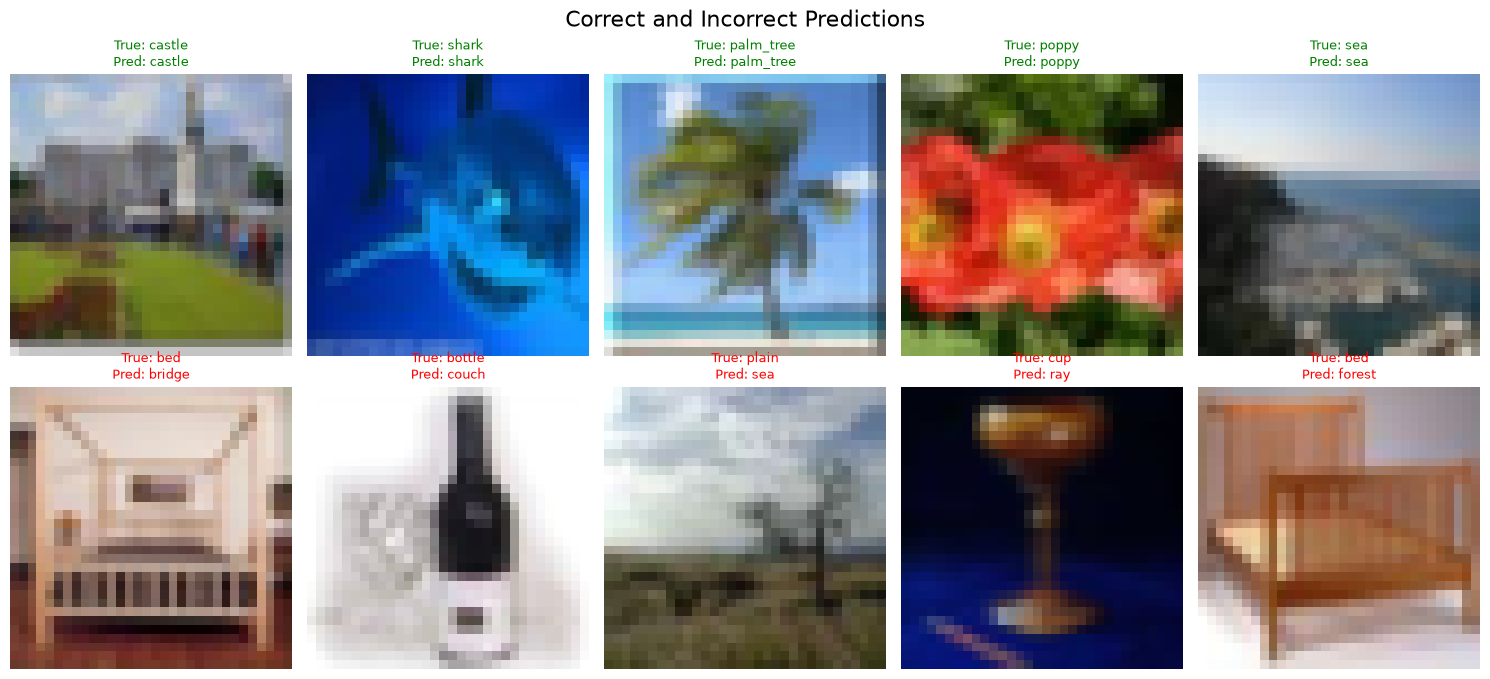

In [32]:
correct_indices = np.where(
    best_y_pred == y_test
)[0]

wrong_indices = np.where(
    best_y_pred != y_test
)[0]

rng = np.random.default_rng(RANDOM_STATE)

selected_correct = rng.choice(
    correct_indices,
    size=min(5, len(correct_indices)),
    replace=False
)

selected_wrong = rng.choice(
    wrong_indices,
    size=min(5, len(wrong_indices)),
    replace=False
)

selected = np.concatenate([
    selected_correct,
    selected_wrong
])

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, idx in zip(axes.flat, selected):
    ax.imshow(X_test_images[idx])

    true_label = class_names[y_test[idx]]
    pred_label = class_names[best_y_pred[idx]]

    ax.set_title(
        f"True: {true_label}\nPred: {pred_label}",
        fontsize=9,
        color=(
            "green"
            if y_test[idx] == best_y_pred[idx]
            else "red"
        )
    )

    ax.axis("off")

for ax in axes.flat[len(selected):]:
    ax.axis("off")

plt.suptitle(
    "Correct and Incorrect Predictions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "prediction_examples.png",
    dpi=300
)

plt.show()

保存分类器及其预处理流程

In [33]:
model_bundle = {
    "classifier": best_model,
    "scaler": scaler,
    "pca": pca if best_feature == "PCA" else None,
    "class_names": class_names,
    "feature_type": best_feature,
    "accuracy": float(best_accuracy)
}

joblib.dump(
    model_bundle,
    RESULT_DIR / "best_model.joblib"
)

print("最优模型保存成功")
print(RESULT_DIR / "best_model.joblib")

最优模型保存成功
/Users/caijingxi/FZU_2026_Autumn/FZU-MachineLearning-2026/mid_project/results/best_model.joblib


验证保存的模型

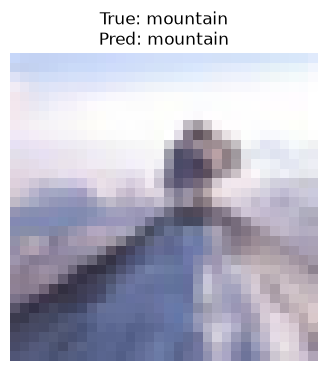

In [34]:
loaded = joblib.load(
    RESULT_DIR / "best_model.joblib"
)

# 取测试集第一张图像
sample_image = X_test_images[0]

# 图像转换为特征
sample = sample_image.reshape(1, -1).astype(
    np.float32
) / 255.0

# 使用训练时的标准化器
sample = loaded["scaler"].transform(sample)

# 需要 PCA 时执行转换
if loaded["pca"] is not None:
    sample = loaded["pca"].transform(sample)

pred = loaded["classifier"].predict(sample)[0]

plt.figure(figsize=(4, 4))
plt.imshow(sample_image)
plt.title(
    f"True: {class_names[y_test[0]]}\n"
    f"Pred: {class_names[pred]}"
)
plt.axis("off")
plt.show()